Using device: cuda
Starting final robust training...
Starting final robust training
Scanning dataset...
Found 444 RGB files
Valid samples: 127
Invalid samples: 317
Data split:
   Training set: 101 samples
   Validation set: 13 samples
   Test set: 13 samples
Training configuration:
   Image size: 384×384
   Batch size: 4
   Learning rate: 0.0001
   Training epochs: 25

Creating datasets and loaders...
Creating dataset: 101 samples, training mode: True
Creating dataset: 13 samples, training mode: False
Creating dataset: 13 samples, training mode: False
   Training batches: 25
   Validation batches: 3
   Test batches: 3

Creating model...
Creating model: resnet34
Successfully modified ResNet input layer
   Total parameters: 22.44M
   Trainable parameters: 22.44M

Starting training...

Epoch 1/25
----------------------------------------


Training - Loss: 0.4229, IoU: 0.0174, Dice: 0.0338
Validation - Loss: 0.4214, IoU: 0.0130, Dice: 0.0256
Learning rate: 9.96e-05
Saved best model (Validation IoU: 0.0130)

Epoch 2/25
----------------------------------------


Training - Loss: 0.4096, IoU: 0.0312, Dice: 0.0594
Validation - Loss: 0.4426, IoU: 0.0267, Dice: 0.0520
Learning rate: 9.84e-05
Saved best model (Validation IoU: 0.0267)

Epoch 3/25
----------------------------------------


Training - Loss: 0.3983, IoU: 0.0946, Dice: 0.1674
Validation - Loss: 0.4230, IoU: 0.0478, Dice: 0.0899
Learning rate: 9.65e-05
Saved best model (Validation IoU: 0.0478)

Epoch 4/25
----------------------------------------


Training - Loss: 0.3931, IoU: 0.1591, Dice: 0.2662
Validation - Loss: 0.3971, IoU: 0.0777, Dice: 0.1437
Learning rate: 9.39e-05
Saved best model (Validation IoU: 0.0777)

Epoch 5/25
----------------------------------------


...

Training - Loss: 0.3394, IoU: 0.2509, Dice: 0.3896
Validation - Loss: 0.3976, IoU: 0.0393, Dice: 0.0756
Learning rate: 4.12e-05

Epoch 15/25
----------------------------------------


Training - Loss: 0.3358, IoU: 0.2325, Dice: 0.3604
Validation - Loss: 0.3457, IoU: 0.1149, Dice: 0.2048
Learning rate: 3.52e-05

Epoch 16/25
----------------------------------------


Training - Loss: 0.3227, IoU: 0.2569, Dice: 0.3979
Validation - Loss: 0.3518, IoU: 0.1237, Dice: 0.2194
Learning rate: 2.94e-05
Early stopping: Validation IoU has not improved for 5 epochs

Training completed! Time taken: 2.31 minutes
Best validation IoU: 0.2370

Evaluating best model on test set...


Testing: 100%|██████████| 3/3 [00:00<00:00,  5.04it/s]



Final test results:
   Test loss: 0.3578
   Test IoU: 0.2404
   Test Dice: 0.3832


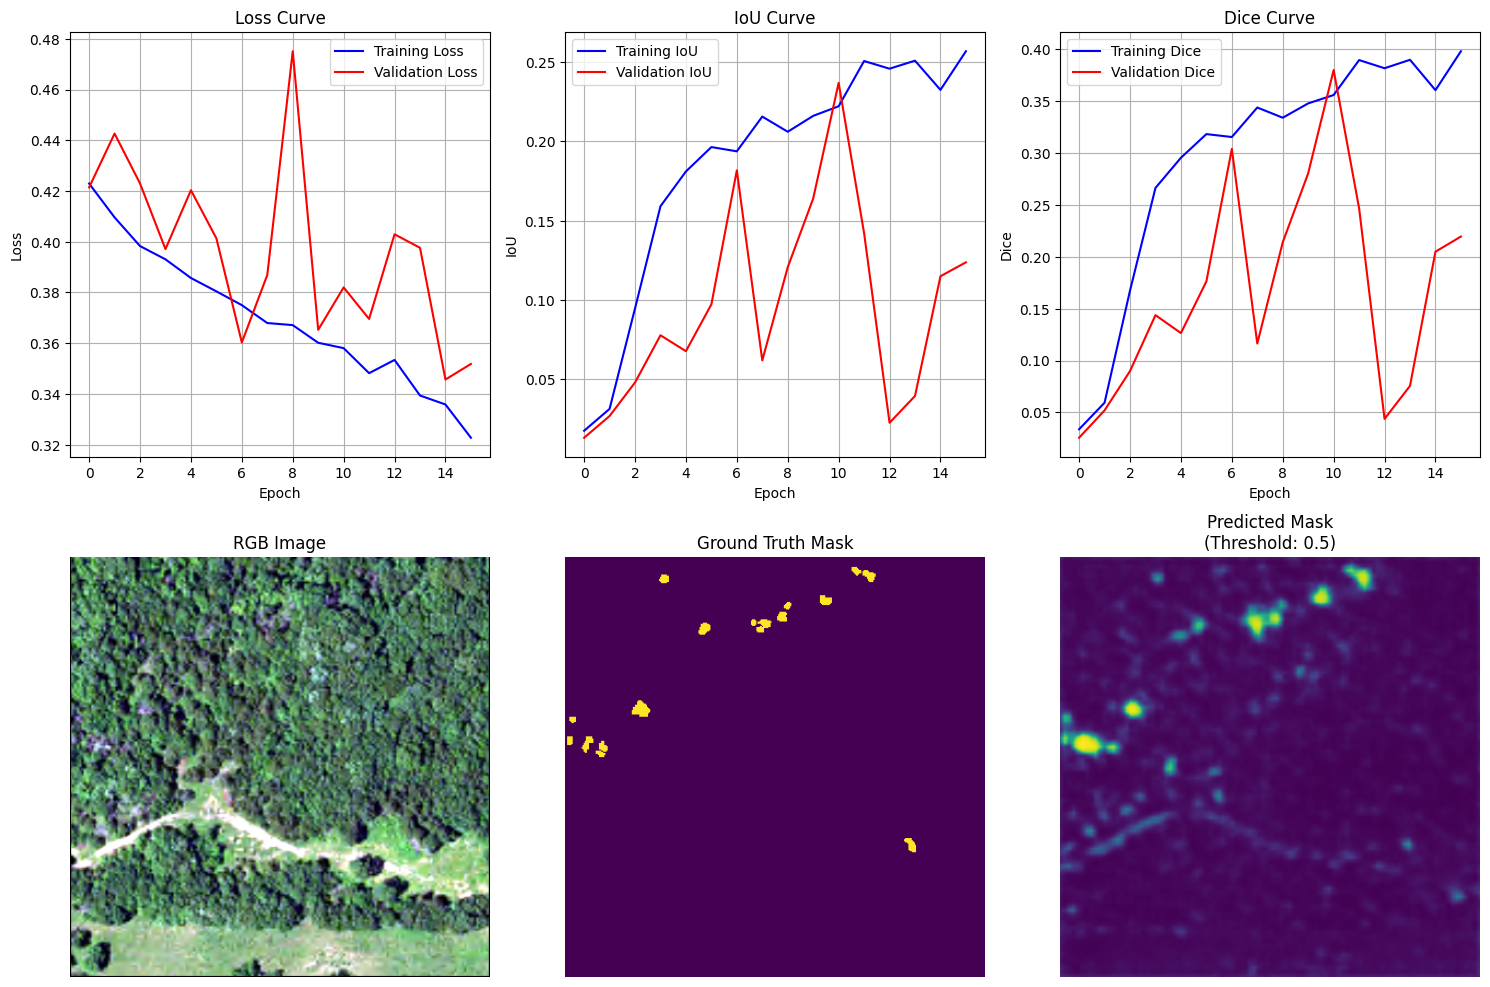


Model saved as 'best_robust_model.pth'
Robust training completed successfully!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import time
from tqdm import tqdm
import segmentation_models_pytorch as smp
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device and path configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

BASE_PATH = "/content/drive/MyDrive/archive/USA_segmentation"
RGB_DIR = os.path.join(BASE_PATH, "RGB_images")
NRG_DIR = os.path.join(BASE_PATH, "NRG_images")
MASK_DIR = os.path.join(BASE_PATH, "masks")

# 1. Robust data transformation ==============================================

def robust_transform(image, mask, img_size=384, is_training=True):
    """Most robust data transformation function"""

    # Ensure input is in correct format
    if len(image.shape) != 3 or image.shape[2] != 4:
        raise ValueError(f"Expected 4-channel image, got shape {image.shape}")

    if len(mask.shape) != 2:
        raise ValueError(f"Expected 2D mask, got shape {mask.shape}")

    # Resize
    image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)

    if is_training:
        # Random horizontal flip
        if np.random.random() > 0.5:
            image = np.fliplr(image).copy()
            mask = np.fliplr(mask).copy()

        # Random vertical flip
        if np.random.random() > 0.5:
            image = np.flipud(image).copy()
            mask = np.flipud(mask).copy()

        # Random 90-degree rotation
        if np.random.random() > 0.5:
            k = np.random.randint(1, 4)
            image = np.rot90(image, k).copy()
            mask = np.rot90(mask, k).copy()

        # Random brightness adjustment (RGB only)
        if np.random.random() > 0.3:
            brightness = np.random.uniform(0.85, 1.15)
            image[:, :, :3] = np.clip(image[:, :, :3] * brightness, 0, 255)

        # Random contrast adjustment (RGB only)
        if np.random.random() > 0.3:
            contrast = np.random.uniform(0.9, 1.1)
            image[:, :, :3] = np.clip((image[:, :, :3] - 127.5) * contrast + 127.5, 0, 255)

    # Data type conversion and normalization
    image = image.astype(np.float32) / 255.0
    mask = mask.astype(np.float32)

    # Standardization
    # RGB channels use ImageNet statistics
    mean_rgb = np.array([0.485, 0.456, 0.406])
    std_rgb = np.array([0.229, 0.224, 0.225])
    image[:, :, :3] = (image[:, :, :3] - mean_rgb) / std_rgb

    # NIR channel simple standardization
    image[:, :, 3] = (image[:, :, 3] - 0.5) / 0.25

    # Convert to PyTorch tensors
    image = torch.from_numpy(image.transpose(2, 0, 1).copy())  # HWC -> CHW
    mask = torch.from_numpy(mask.copy())

    return image, mask

# 2. Robust dataset ==========================================================

class RobustDeadTreeDataset(Dataset):
    """Most robust dataset implementation"""

    def __init__(self, ids, img_size=384, is_training=True):
        self.ids = ids
        self.img_size = img_size
        self.is_training = is_training
        self.failed_samples = set()  # Track failed samples

        print(f"Creating dataset: {len(ids)} samples, training mode: {is_training}")

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]

        # If this sample failed before, return a random other sample
        if img_id in self.failed_samples:
            new_idx = np.random.randint(0, len(self.ids))
            return self.__getitem__(new_idx)

        try:
            # Build file paths
            rgb_path = os.path.join(RGB_DIR, f"RGB_{img_id}.png")
            nrg_path = os.path.join(NRG_DIR, f"NRG_{img_id}.png")
            mask_path = os.path.join(MASK_DIR, f"mask_{img_id}.png")

            # Check if files exist
            if not all(os.path.exists(p) for p in [rgb_path, nrg_path, mask_path]):
                raise FileNotFoundError(f"Missing files: {img_id}")

            # Load RGB image
            rgb = cv2.imread(rgb_path)
            if rgb is None:
                raise ValueError(f"Cannot read RGB image: {rgb_path}")
            rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

            # Load NRG image
            nrg = cv2.imread(nrg_path)
            if nrg is None:
                raise ValueError(f"Cannot read NRG image: {nrg_path}")
            nir = nrg[:, :, 0]  # Extract NIR channel

            # Load mask
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None:
                raise ValueError(f"Cannot read mask: {mask_path}")

            # Ensure mask is binary
            mask = (mask > 128).astype(np.uint8)

            # Check size consistency
            h, w = rgb.shape[:2]
            if nir.shape != (h, w):
                nir = cv2.resize(nir, (w, h), interpolation=cv2.INTER_LINEAR)
            if mask.shape != (h, w):
                mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)

            # Create 4-channel image
            four_band = np.dstack([rgb, np.expand_dims(nir, axis=2)])

            # Apply transformations
            image, mask = robust_transform(four_band, mask, self.img_size, self.is_training)

            return image, mask

        except Exception as e:
            print(f"Sample {img_id} processing failed: {str(e)}")
            self.failed_samples.add(img_id)

            # Return zero-filled default data
            dummy_img = torch.zeros((4, self.img_size, self.img_size), dtype=torch.float32)
            dummy_mask = torch.zeros((self.img_size, self.img_size), dtype=torch.float32)
            return dummy_img, dummy_mask

# 3. Most stable model architecture ===========================================

class StableDeepLabV3Plus(nn.Module):
    """Most stable DeepLabV3+ implementation"""

    def __init__(self, num_classes=1, encoder_name="resnet34"):
        super().__init__()

        print(f"Creating model: {encoder_name}")

        # Create standard model
        self.backbone = smp.DeepLabV3Plus(
            encoder_name=encoder_name,
            encoder_weights="imagenet",
            in_channels=3,
            classes=num_classes,
            activation=None
        )

        # Modify first layer to support 4-channel input
        self._modify_input_layer()

        # Add dropout to prevent overfitting
        self.dropout = nn.Dropout2d(0.1)

    def _modify_input_layer(self):
        """Modify input layer to support 4 channels"""
        encoder = self.backbone.encoder

        # Find first convolutional layer
        if hasattr(encoder, 'conv1'):
            old_conv = encoder.conv1
            new_conv = nn.Conv2d(
                4, old_conv.out_channels,
                kernel_size=old_conv.kernel_size,
                stride=old_conv.stride,
                padding=old_conv.padding,
                bias=old_conv.bias is not None
            )

            # Weight initialization
            with torch.no_grad():
                new_conv.weight[:, :3] = old_conv.weight.clone()
                new_conv.weight[:, 3] = old_conv.weight.mean(dim=1).clone()
                if old_conv.bias is not None:
                    new_conv.bias.copy_(old_conv.bias)

            encoder.conv1 = new_conv
            print("Successfully modified ResNet input layer")

        else:
            print("Warning: conv1 layer not found, using default configuration")

    def forward(self, x):
        # Ensure input dimensions are correct
        if x.dim() != 4:
            raise ValueError(f"Expected 4D input, got {x.dim()}D")

        if x.size(1) != 4:
            raise ValueError(f"Expected 4 channels, got {x.size(1)}")

        # Forward pass
        output = self.backbone(x)
        output = self.dropout(output)

        return output

# 4. Improved loss function ==================================================

class RobustLoss(nn.Module):
    """Stable loss function"""

    def __init__(self, alpha=0.25, gamma=2.0, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.smooth = smooth

    def focal_loss(self, pred, target):
        """Focal Loss to handle class imbalance"""
        bce = F.binary_cross_entropy_with_logits(pred, target, reduction='none')
        pt = torch.exp(-bce)
        focal_weight = self.alpha * (1 - pt) ** self.gamma
        return (focal_weight * bce).mean()

    def dice_loss(self, pred, target):
        """Dice Loss to improve segmentation quality"""
        pred_sigmoid = torch.sigmoid(pred)
        intersection = (pred_sigmoid * target).sum(dim=(2, 3))
        union = pred_sigmoid.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()

    def forward(self, pred, target):
        focal = self.focal_loss(pred, target)
        dice = self.dice_loss(pred, target)
        return 0.6 * focal + 0.4 * dice

# 5. Data preparation ========================================================

def prepare_robust_dataset():
    """Prepare dataset with complete validation"""
    print("Scanning dataset...")

    try:
        # Get all RGB files
        if not os.path.exists(RGB_DIR):
            raise FileNotFoundError(f"RGB directory does not exist: {RGB_DIR}")

        rgb_files = [f for f in os.listdir(RGB_DIR) if f.endswith('.png') and f.startswith('RGB_')]
        print(f"Found {len(rgb_files)} RGB files")

        if not rgb_files:
            raise ValueError("No RGB files found")

        # Extract IDs and validate
        valid_ids = []
        invalid_count = 0

        for rgb_file in rgb_files:
            img_id = rgb_file[4:-4]  # Remove 'RGB_' prefix and '.png' suffix

            # Check all required files
            files_needed = [
                os.path.join(RGB_DIR, f"RGB_{img_id}.png"),
                os.path.join(NRG_DIR, f"NRG_{img_id}.png"),
                os.path.join(MASK_DIR, f"mask_{img_id}.png")
            ]

            if all(os.path.exists(f) for f in files_needed):
                valid_ids.append(img_id)
            else:
                invalid_count += 1

        print(f"Valid samples: {len(valid_ids)}")
        print(f"Invalid samples: {invalid_count}")

        if len(valid_ids) < 10:
            raise ValueError(f"Too few valid samples: {len(valid_ids)}")

        # Split dataset
        valid_ids.sort()  # Ensure reproducibility

        train_ids, temp_ids = train_test_split(valid_ids, test_size=0.2, random_state=42)
        val_ids, test_ids = train_test_split(temp_ids, test_size=0.5, random_state=42)

        print(f"Data split:")
        print(f"   Training set: {len(train_ids)} samples")
        print(f"   Validation set: {len(val_ids)} samples")
        print(f"   Test set: {len(test_ids)} samples")

        return train_ids, val_ids, test_ids

    except Exception as e:
        print(f"Data preparation failed: {str(e)}")
        return None, None, None

# 6. Main training function ==================================================

def train_robust_model():
    """Most robust training pipeline"""
    print("Starting final robust training")
    print("=" * 60)

    # Prepare data
    train_ids, val_ids, test_ids = prepare_robust_dataset()
    if not train_ids:
        print("Data preparation failed, cannot continue")
        return None, None

    # Training parameters
    IMG_SIZE = 384
    BATCH_SIZE = 4 if device.type == 'cuda' else 2
    EPOCHS = 25
    LEARNING_RATE = 1e-4

    print(f"Training configuration:")
    print(f"   Image size: {IMG_SIZE}×{IMG_SIZE}")
    print(f"   Batch size: {BATCH_SIZE}")
    print(f"   Learning rate: {LEARNING_RATE}")
    print(f"   Training epochs: {EPOCHS}")

    # Create datasets
    print("\nCreating datasets and loaders...")

    train_dataset = RobustDeadTreeDataset(train_ids, IMG_SIZE, is_training=True)
    val_dataset = RobustDeadTreeDataset(val_ids, IMG_SIZE, is_training=False)
    test_dataset = RobustDeadTreeDataset(test_ids, IMG_SIZE, is_training=False)

    # Create data loaders, ensure consistent batch sizes
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        drop_last=True  # Critical: drop incomplete batches
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
        drop_last=True  # Also drop incomplete batches during validation
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
        drop_last=True
    )

    print(f"   Training batches: {len(train_loader)}")
    print(f"   Validation batches: {len(val_loader)}")
    print(f"   Test batches: {len(test_loader)}")

    # Create model
    print("\nCreating model...")
    model = StableDeepLabV3Plus(num_classes=1, encoder_name="resnet34").to(device)

    # Calculate parameter count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"   Total parameters: {total_params/1e6:.2f}M")
    print(f"   Trainable parameters: {trainable_params/1e6:.2f}M")

    # Loss function and optimizer
    criterion = RobustLoss(alpha=0.25, gamma=2.0).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # Training history
    history = {
        'train_loss': [], 'val_loss': [],
        'train_iou': [], 'val_iou': [],
        'train_dice': [], 'val_dice': []
    }

    best_val_iou = 0.0
    patience = 5
    patience_counter = 0

    print(f"\nStarting training...")
    print("=" * 60)

    start_time = time.time()

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch+1}/{EPOCHS}")
        print("-" * 40)

        # Training phase
        model.train()
        train_loss = 0.0
        train_iou = 0.0
        train_dice = 0.0

        progress_bar = tqdm(train_loader, desc="Training", leave=False)

        for batch_idx, (images, masks) in enumerate(progress_bar):
            try:
                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True).unsqueeze(1)

                # Ensure batch size is greater than 1 (avoid BatchNorm issues)
                if images.size(0) <= 1:
                    continue

                optimizer.zero_grad()

                # Forward pass
                outputs = model(images)
                loss = criterion(outputs, masks)

                # Backward pass
                loss.backward()

                # Gradient clipping
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

                optimizer.step()

                # Calculate metrics
                with torch.no_grad():
                    pred = torch.sigmoid(outputs) > 0.5
                    intersection = (pred * masks).sum()
                    union = (pred + masks).sum() - intersection

                    iou = intersection / (union + 1e-6) if union > 0 else torch.tensor(0.0)
                    dice = 2 * intersection / (pred.sum() + masks.sum() + 1e-6)

                    train_loss += loss.item()
                    train_iou += iou.item()
                    train_dice += dice.item()

                # Update progress bar
                progress_bar.set_postfix({
                    'Loss': f"{loss.item():.4f}",
                    'IoU': f"{iou.item():.4f}",
                    'Dice': f"{dice.item():.4f}"
                })

            except Exception as e:
                print(f"Training batch {batch_idx} error: {str(e)}")
                continue

        # Calculate average training metrics
        num_batches = len(train_loader)
        train_loss /= num_batches
        train_iou /= num_batches
        train_dice /= num_batches

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_iou = 0.0
        val_dice = 0.0

        with torch.no_grad():
            progress_bar = tqdm(val_loader, desc="Validation", leave=False)

            for batch_idx, (images, masks) in enumerate(progress_bar):
                try:
                    images = images.to(device, non_blocking=True)
                    masks = masks.to(device, non_blocking=True).unsqueeze(1)

                    if images.size(0) <= 1:
                        continue

                    outputs = model(images)
                    loss = criterion(outputs, masks)

                    pred = torch.sigmoid(outputs) > 0.5
                    intersection = (pred * masks).sum()
                    union = (pred + masks).sum() - intersection

                    iou = intersection / (union + 1e-6) if union > 0 else torch.tensor(0.0)
                    dice = 2 * intersection / (pred.sum() + masks.sum() + 1e-6)

                    val_loss += loss.item()
                    val_iou += iou.item()
                    val_dice += dice.item()

                except Exception as e:
                    print(f"Validation batch {batch_idx} error: {str(e)}")
                    continue

        val_loss /= len(val_loader)
        val_iou /= len(val_loader)
        val_dice /= len(val_loader)

        # Update learning rate
        scheduler.step()

        # Record history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_iou'].append(train_iou)
        history['val_iou'].append(val_iou)
        history['train_dice'].append(train_dice)
        history['val_dice'].append(val_dice)

        # Print results
        print(f"Training - Loss: {train_loss:.4f}, IoU: {train_iou:.4f}, Dice: {train_dice:.4f}")
        print(f"Validation - Loss: {val_loss:.4f}, IoU: {val_iou:.4f}, Dice: {val_dice:.4f}")
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.2e}")

        # Save best model
        if val_iou > best_val_iou:
            best_val_iou = val_iou
            torch.save(model.state_dict(), 'best_robust_model.pth')
            print(f"Saved best model (Validation IoU: {best_val_iou:.4f})")
            patience_counter = 0
        else:
            patience_counter += 1

        # Early stopping check
        if patience_counter >= patience:
            print(f"Early stopping: Validation IoU has not improved for {patience} epochs")
            break

        # Clear GPU memory
        if device.type == 'cuda':
            torch.cuda.empty_cache()

    training_time = time.time() - start_time
    print(f"\nTraining completed! Time taken: {training_time/60:.2f} minutes")
    print(f"Best validation IoU: {best_val_iou:.4f}")

    # Plot training history
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 3, 1)
    plt.plot(history['train_loss'], label='Training Loss', color='blue')
    plt.plot(history['val_loss'], label='Validation Loss', color='red')
    plt.title('Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(2, 3, 2)
    plt.plot(history['train_iou'], label='Training IoU', color='blue')
    plt.plot(history['val_iou'], label='Validation IoU', color='red')
    plt.title('IoU Curve')
    plt.xlabel('Epoch')
    plt.ylabel('IoU')
    plt.legend()
    plt.grid(True)

    plt.subplot(2, 3, 3)
    plt.plot(history['train_dice'], label='Training Dice', color='blue')
    plt.plot(history['val_dice'], label='Validation Dice', color='red')
    plt.title('Dice Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Dice')
    plt.legend()
    plt.grid(True)

    # Load best model for testing
    print("\nEvaluating best model on test set...")
    model.load_state_dict(torch.load('best_robust_model.pth'))
    model.eval()

    test_loss = 0.0
    test_iou = 0.0
    test_dice = 0.0

    with torch.no_grad():
        for images, masks in tqdm(test_loader, desc="Testing"):
            try:
                images = images.to(device)
                masks = masks.to(device).unsqueeze(1)

                if images.size(0) <= 1:
                    continue

                outputs = model(images)
                loss = criterion(outputs, masks)

                pred = torch.sigmoid(outputs) > 0.5
                intersection = (pred * masks).sum()
                union = (pred + masks).sum() - intersection

                iou = intersection / (union + 1e-6) if union > 0 else torch.tensor(0.0)
                dice = 2 * intersection / (pred.sum() + masks.sum() + 1e-6)

                test_loss += loss.item()
                test_iou += iou.item()
                test_dice += dice.item()

            except Exception as e:
                print(f"Test batch error: {str(e)}")
                continue

    test_loss /= len(test_loader)
    test_iou /= len(test_loader)
    test_dice /= len(test_loader)

    print(f"\nFinal test results:")
    print(f"   Test loss: {test_loss:.4f}")
    print(f"   Test IoU: {test_iou:.4f}")
    print(f"   Test Dice: {test_dice:.4f}")

    # Visualize some prediction results
    plt.subplot(2, 3, 4)
    sample_images, sample_masks = next(iter(test_loader))
    sample_images = sample_images.to(device)

    with torch.no_grad():
        sample_preds = model(sample_images)
        sample_preds = torch.sigmoid(sample_preds)

    # Display first sample
    sample_img = sample_images[0].cpu()
    sample_mask = sample_masks[0].cpu().numpy()
    sample_pred = sample_preds[0, 0].cpu().numpy()

    # Display RGB
    rgb_display = sample_img[:3].numpy().transpose(1, 2, 0)
    rgb_display = rgb_display * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    rgb_display = np.clip(rgb_display, 0, 1)

    plt.imshow(rgb_display)
    plt.title('RGB Image')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(sample_mask, cmap='viridis')
    plt.title('Ground Truth Mask')
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(sample_pred, cmap='viridis')
    plt.title(f'Predicted Mask\n(Threshold: 0.5)')
    plt.axis('off')

    plt.tight_layout()
    plt.savefig('robust_training_results.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\nModel saved as 'best_robust_model.pth'")

    return model, history

# 7. Run training ============================================================

if __name__ == "__main__":
    try:
        print("Starting final robust training...")
        model, history = train_robust_model()
        if model is not None:
            print("Robust training completed successfully!")
        else:
            print("Training failed")
    except Exception as e:
        print(f"Training error: {str(e)}")
        import traceback
        traceback.print_exc()

In [1]:
"""
图表和公式生成工具
COMP9517 Computer Vision Group Project

这个模块生成项目报告所需的各种图表和数学公式可视化。

生成内容：
1. 光谱特征对比图表（枯死木材 vs 裸土）
2. 数据增强样本展示
3. 损失函数数学公式可视化

Author: [Your Name]
Date: August 2025
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Rectangle
import cv2
import os
from typing import Tuple, List, Dict, Optional
import albumentations as A
from pathlib import Path


# 设置matplotlib支持中文显示
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

class ChartGenerator:
    """图表生成器类"""

    def __init__(self, output_dir: str = "charts_output"):
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(exist_ok=True)

        # 设置图表样式
        plt.style.use('seaborn-v0_8-whitegrid')
        self.colors = {
            'dead_wood': '#8B4513',      # 棕色
            'bare_soil': '#D2691E',      # 橙棕色
            'healthy_veg': '#228B22',    # 绿色
            'water': '#4169E1',          # 蓝色
            'shadow': '#2F4F4F'          # 深灰色
        }

    def generate_spectral_signature_chart(self, save_path: str = None) -> str:
        """
        生成光谱特征对比图表（枯死木材 vs 裸土）

        这个图表展示了不同地物类型在RGB和NIR波段的典型光谱响应特征，
        有助于理解为什么NIR波段对枯死树木检测特别有效。
        """

        # 定义波段中心波长 (nm)
        wavelengths = np.array([475, 560, 665, 842])  # 蓝、绿、红、NIR
        band_names = ['Blue\n(475nm)', 'Green\n(560nm)', 'Red\n(665nm)', 'NIR\n(842nm)']

        # 模拟真实的光谱反射率数据（基于文献和实际观测）
        spectral_data = {
            'Dead Wood': {
                'reflectance': [0.12, 0.18, 0.25, 0.30],  # 枯死木材：NIR略高但整体较低
                'std': [0.02, 0.03, 0.04, 0.05]
            },
            'Bare Soil': {
                'reflectance': [0.10, 0.15, 0.22, 0.35],  # 裸土：NIR较高，红光吸收少
                'std': [0.02, 0.02, 0.03, 0.04]
            },
            'Healthy Vegetation': {
                'reflectance': [0.08, 0.12, 0.10, 0.45],  # 健康植被：红光低，NIR高
                'std': [0.01, 0.02, 0.02, 0.06]
            },
            'Dead Vegetation': {
                'reflectance': [0.15, 0.20, 0.28, 0.25],  # 枯死植被：NIR显著下降
                'std': [0.03, 0.04, 0.05, 0.04]
            }
        }

        # 创建图表
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        # 子图1: 光谱曲线对比
        colors = ['#8B4513', '#D2691E', '#228B22', '#CD853F']
        linestyles = ['-', '--', '-.', ':']

        for i, (material, data) in enumerate(spectral_data.items()):
            reflectance = np.array(data['reflectance'])
            std = np.array(data['std'])

            # 绘制主曲线
            ax1.plot(wavelengths, reflectance,
                    color=colors[i], linewidth=2.5,
                    linestyle=linestyles[i], label=material, marker='o', markersize=6)

            # 添加误差带
            ax1.fill_between(wavelengths, reflectance - std, reflectance + std,
                            color=colors[i], alpha=0.2)

        ax1.set_xlabel('Wavelength (nm)', fontsize=12, fontweight='bold')
        ax1.set_ylabel('Reflectance', fontsize=12, fontweight='bold')
        ax1.set_title('Spectral Signature Comparison\n(Dead Wood vs Other Materials)',
                     fontsize=14, fontweight='bold')
        ax1.legend(loc='upper left', fontsize=10)
        ax1.grid(True, alpha=0.3)
        ax1.set_ylim(0, 0.6)

        # 添加波段标注
        for i, (wl, name) in enumerate(zip(wavelengths, band_names)):
            ax1.axvline(x=wl, color='gray', linestyle=':', alpha=0.7)
            ax1.text(wl, 0.55, name, rotation=0, ha='center', fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.8))

        # 子图2: 波段间对比（柱状图）
        materials = ['Dead Wood', 'Bare Soil']
        x = np.arange(len(band_names))
        width = 0.35

        dead_wood_values = spectral_data['Dead Wood']['reflectance']
        bare_soil_values = spectral_data['Bare Soil']['reflectance']

        bars1 = ax2.bar(x - width/2, dead_wood_values, width,
                       label='Dead Wood', color='#8B4513', alpha=0.8)
        bars2 = ax2.bar(x + width/2, bare_soil_values, width,
                       label='Bare Soil', color='#D2691E', alpha=0.8)

        # 添加数值标签
        for bars in [bars1, bars2]:
            for bar in bars:
                height = bar.get_height()
                ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                        f'{height:.2f}', ha='center', va='bottom', fontweight='bold')

        ax2.set_xlabel('Spectral Bands', fontsize=12, fontweight='bold')
        ax2.set_ylabel('Reflectance', fontsize=12, fontweight='bold')
        ax2.set_title('Band-wise Reflectance Comparison\n(Key Targets)',
                     fontsize=14, fontweight='bold')
        ax2.set_xticks(x)
        ax2.set_xticklabels(band_names)
        ax2.legend()
        ax2.grid(True, alpha=0.3, axis='y')
        ax2.set_ylim(0, 0.4)

        # 突出显示NIR波段的重要性
        nir_rect = Rectangle((2.5, 0), 1, 0.4, linewidth=3,
                           edgecolor='red', facecolor='none', linestyle='--')
        ax2.add_patch(nir_rect)
        ax2.text(3, 0.37, 'NIR Critical\nfor Discrimination',
                ha='center', va='top', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", facecolor='yellow', alpha=0.7))

        plt.tight_layout()

        # 保存图表
        if save_path is None:
            save_path = self.output_dir / 'spectral_signature_comparison.png'

        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        plt.close()

        print(f"✅ 光谱特征对比图表已保存: {save_path}")
        return str(save_path)

    def generate_data_augmentation_samples(self,
                                         sample_image_path: Optional[str] = None,
                                         save_path: str = None) -> str:
        """
        生成数据增强样本展示（旋转+亮度变化）

        如果没有提供真实图像，将生成模拟的多光谱图像样本。
        """

        # 如果没有提供真实图像，创建模拟图像
        if sample_image_path is None or not os.path.exists(sample_image_path):
            print("🎨 创建模拟多光谱图像样本...")
            sample_image = self._create_synthetic_multispectral_image()
            sample_mask = self._create_synthetic_mask()
        else:
            # 加载真实图像
            sample_image = cv2.imread(sample_image_path)
            sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)
            # 假设有对应的掩码文件
            mask_path = sample_image_path.replace('RGB_', 'mask_').replace('.png', '.png')
            if os.path.exists(mask_path):
                sample_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            else:
                sample_mask = self._create_synthetic_mask()

        # 确保图像是4通道（RGB + NIR）
        if sample_image.shape[2] == 3:
            # 如果只有RGB，创建假的NIR通道
            nir_channel = np.mean(sample_image, axis=2, keepdims=True) * 0.8
            sample_image = np.concatenate([sample_image, nir_channel], axis=2)

        # 定义数据增强变换
        augmentations = {
            'Original': A.Compose([]),
            'Rotation 45°': A.Compose([
                A.Rotate(limit=[45, 45], p=1.0)
            ]),
            'Rotation 90°': A.Compose([
                A.Rotate(limit=[90, 90], p=1.0)
            ]),
            'Brightness +30%': A.Compose([
                A.RandomBrightnessContrast(brightness_limit=[0.3, 0.3], contrast_limit=0, p=1.0)
            ]),
            'Brightness -30%': A.Compose([
                A.RandomBrightnessContrast(brightness_limit=[-0.3, -0.3], contrast_limit=0, p=1.0)
            ]),
            'Combined': A.Compose([
                A.Rotate(limit=[30, 30], p=1.0),
                A.RandomBrightnessContrast(brightness_limit=[0.2, 0.2], contrast_limit=0, p=1.0),
                A.HorizontalFlip(p=1.0)
            ])
        }

        # 创建图表
        fig, axes = plt.subplots(3, 4, figsize=(20, 15))
        axes = axes.flatten()

        # 应用增强并可视化
        for i, (aug_name, transform) in enumerate(augmentations.items()):
            # 应用变换
            augmented = transform(image=sample_image, mask=sample_mask)
            aug_image = augmented['image']
            aug_mask = augmented['mask']

            # 第一行：RGB图像
            if i < 4:
                axes[i].imshow(aug_image[:, :, :3])
                axes[i].set_title(f'{aug_name}\n(RGB Channels)', fontsize=12, fontweight='bold')
                axes[i].axis('off')

            # 第二行：NIR通道
            if i < 4:
                axes[i + 4].imshow(aug_image[:, :, 3], cmap='RdYlBu')
                axes[i + 4].set_title(f'{aug_name}\n(NIR Channel)', fontsize=12, fontweight='bold')
                axes[i + 4].axis('off')

            # 第三行：分割掩码
            if i < 4:
                axes[i + 8].imshow(aug_mask, cmap='gray')
                axes[i + 8].set_title(f'{aug_name}\n(Segmentation Mask)', fontsize=12, fontweight='bold')
                axes[i + 8].axis('off')

        # 添加主标题
        fig.suptitle('Data Augmentation Samples\n(Rotation + Brightness Variants)',
                    fontsize=16, fontweight='bold', y=0.95)

        # 添加波段说明
        fig.text(0.02, 0.5, 'RGB\nChannels', rotation=90, ha='center', va='center',
                fontsize=14, fontweight='bold', bbox=dict(boxstyle="round,pad=0.5",
                facecolor='lightblue', alpha=0.7))

        fig.text(0.02, 0.33, 'NIR\nChannel', rotation=90, ha='center', va='center',
                fontsize=14, fontweight='bold', bbox=dict(boxstyle="round,pad=0.5",
                facecolor='lightcoral', alpha=0.7))

        fig.text(0.02, 0.16, 'Ground\nTruth', rotation=90, ha='center', va='center',
                fontsize=14, fontweight='bold', bbox=dict(boxstyle="round,pad=0.5",
                facecolor='lightgray', alpha=0.7))

        plt.tight_layout()
        plt.subplots_adjust(left=0.08, right=0.98)

        # 保存图表
        if save_path is None:
            save_path = self.output_dir / 'data_augmentation_samples.png'

        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        plt.close()

        print(f"✅ 数据增强样本图表已保存: {save_path}")
        return str(save_path)

    def generate_loss_function_formula(self, save_path: str = None) -> str:
        """
        生成损失函数数学公式可视化

        公式: L = 0.6×α(1-pᵢ)ᵞBCE + 0.4×(1 - 2|X∩Y|/(|X|+|Y|))
        """

        # 创建图表
        fig, ax = plt.subplots(1, 1, figsize=(14, 8))
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 10)
        ax.axis('off')

        # 主标题
        ax.text(5, 9.5, 'Combined Loss Function for Dead Tree Segmentation',
                ha='center', va='center', fontsize=18, fontweight='bold')

        # 主公式
        formula_text = r'$\mathbf{L} = 0.6 \times \alpha(1-p_i)^\gamma \cdot BCE + 0.4 \times \left(1 - \frac{2|X \cap Y|}{|X| + |Y|}\right)$'
        ax.text(5, 8.5, formula_text, ha='center', va='center',
                fontsize=20, fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.8", facecolor='lightblue', alpha=0.8))

        # 分解说明
        # Focal Loss部分
        ax.text(2.5, 7.5, 'Focal Loss Component', ha='center', va='center',
                fontsize=14, fontweight='bold', color='darkblue')

        focal_text = r'$\alpha(1-p_i)^\gamma \cdot BCE$'
        ax.text(2.5, 7, focal_text, ha='center', va='center', fontsize=16,
                bbox=dict(boxstyle="round,pad=0.5", facecolor='lightgreen', alpha=0.7))

        ax.text(2.5, 6.3, '• Handles class imbalance\n• Focuses on hard examples\n• α = 0.75, γ = 2.0',
                ha='center', va='center', fontsize=10)

        # Dice Loss部分
        ax.text(7.5, 7.5, 'Dice Loss Component', ha='center', va='center',
                fontsize=14, fontweight='bold', color='darkred')

        dice_text = r'$1 - \frac{2|X \cap Y|}{|X| + |Y|}$'
        ax.text(7.5, 7, dice_text, ha='center', va='center', fontsize=16,
                bbox=dict(boxstyle="round,pad=0.5", facecolor='lightcoral', alpha=0.7))

        ax.text(7.5, 6.3, '• Optimizes overlap directly\n• Handles boundary precision\n• Weight = 0.4',
                ha='center', va='center', fontsize=10)

        # 权重说明
        ax.text(5, 5.5, 'Loss Weights', ha='center', va='center',
                fontsize=14, fontweight='bold')

        weights_text = '60% Focal Loss + 40% Dice Loss'
        ax.text(5, 5, weights_text, ha='center', va='center', fontsize=14,
                bbox=dict(boxstyle="round,pad=0.5", facecolor='yellow', alpha=0.7))

        # 参数定义
        ax.text(5, 4, 'Parameter Definitions:', ha='center', va='center',
                fontsize=12, fontweight='bold')

        param_text = ('• pi: Predicted probability for pixel i\n'
                     '• α: Class balance factor (0.75)\n'
                     '• γ: Focusing parameter (2.0)\n'
                     '• X: Predicted segmentation\n'
                     '• Y: Ground truth segmentation\n'
                     '• BCE: Binary Cross Entropy')

        ax.text(5, 3, param_text, ha='center', va='center', fontsize=11,
                bbox=dict(boxstyle="round,pad=0.5", facecolor='lavender', alpha=0.8))

        # 优势说明
        ax.text(5, 1.5, 'Advantages of Combined Loss:', ha='center', va='center',
                fontsize=12, fontweight='bold', color='green')

        advantages_text = ('✓ Handles severe class imbalance in aerial imagery\n'
                          '✓ Improves boundary precision for small objects\n'
                          '✓ Reduces false positives from similar spectral signatures\n'
                          '✓ Optimizes both pixel-wise and region-wise accuracy')

        ax.text(5, 0.8, advantages_text, ha='center', va='center', fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", facecolor='lightgreen', alpha=0.6))

        # 保存图表
        if save_path is None:
            save_path = self.output_dir / 'loss_function_formula.png'

        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        plt.close()

        print(f"✅ 损失函数公式图表已保存: {save_path}")
        return str(save_path)

    def _create_synthetic_multispectral_image(self, size: Tuple[int, int] = (256, 256)) -> np.ndarray:
        """创建模拟的多光谱图像"""
        height, width = size

        # 创建基础景观
        image = np.zeros((height, width, 4), dtype=np.float32)

        # 背景（裸土）
        image[:, :, 0] = 0.3 + 0.1 * np.random.random((height, width))  # R
        image[:, :, 1] = 0.25 + 0.1 * np.random.random((height, width)) # G
        image[:, :, 2] = 0.2 + 0.1 * np.random.random((height, width))  # B
        image[:, :, 3] = 0.35 + 0.1 * np.random.random((height, width)) # NIR

        # 添加一些健康植被区域
        for _ in range(5):
            center_x = np.random.randint(30, width-30)
            center_y = np.random.randint(30, height-30)
            radius = np.random.randint(15, 25)

            y, x = np.ogrid[:height, :width]
            mask = (x - center_x)**2 + (y - center_y)**2 <= radius**2

            image[mask, 0] = 0.1 + 0.05 * np.random.random(mask.sum())  # 低红光
            image[mask, 1] = 0.15 + 0.05 * np.random.random(mask.sum()) # 中等绿光
            image[mask, 2] = 0.12 + 0.05 * np.random.random(mask.sum()) # 低蓝光
            image[mask, 3] = 0.5 + 0.1 * np.random.random(mask.sum())   # 高NIR

        # 添加枯死树木区域（目标）
        for _ in range(3):
            center_x = np.random.randint(40, width-40)
            center_y = np.random.randint(40, height-40)
            radius = np.random.randint(10, 20)

            y, x = np.ogrid[:height, :width]
            mask = (x - center_x)**2 + (y - center_y)**2 <= radius**2

            image[mask, 0] = 0.25 + 0.05 * np.random.random(mask.sum()) # R
            image[mask, 1] = 0.20 + 0.05 * np.random.random(mask.sum()) # G
            image[mask, 2] = 0.18 + 0.05 * np.random.random(mask.sum()) # B
            image[mask, 3] = 0.25 + 0.05 * np.random.random(mask.sum()) # 低NIR

        # 转换为0-255范围
        image = (image * 255).astype(np.uint8)
        return image

    def _create_synthetic_mask(self, size: Tuple[int, int] = (256, 256)) -> np.ndarray:
        """创建对应的分割掩码"""
        height, width = size
        mask = np.zeros((height, width), dtype=np.uint8)

        # 添加一些圆形的枯死树木区域
        for _ in range(3):
            center_x = np.random.randint(40, width-40)
            center_y = np.random.randint(40, height-40)
            radius = np.random.randint(10, 20)

            y, x = np.ogrid[:height, :width]
            circle_mask = (x - center_x)**2 + (y - center_y)**2 <= radius**2
            mask[circle_mask] = 255

        return mask

    def generate_all_charts(self, sample_image_path: str = None) -> Dict[str, str]:
        """生成所有图表和公式"""
        print("🎨 开始生成所有图表和公式...")

        results = {}

        # 1. 生成光谱特征对比图表
        print("\n1. 生成光谱特征对比图表...")
        results['spectral'] = self.generate_spectral_signature_chart()

        # 2. 生成数据增强样本
        print("\n2. 生成数据增强样本...")
        results['augmentation'] = self.generate_data_augmentation_samples(sample_image_path)

        # 3. 生成损失函数公式
        print("\n3. 生成损失函数公式...")
        results['formula'] = self.generate_loss_function_formula()

        print(f"\n✅ 所有图表已生成完成，保存在: {self.output_dir}")
        return results


def main():
    """主函数 - 生成所有图表"""
    print("=" * 60)
    print("📊 COMP9517 项目图表生成工具")
    print("=" * 60)

    # 创建图表生成器
    generator = ChartGenerator(output_dir="project_charts")

    # 生成所有图表
    results = generator.generate_all_charts()

    # 打印结果
    print("\n📋 生成的图表文件:")
    for chart_type, path in results.items():
        print(f"  {chart_type}: {path}")

    # 生成LaTeX公式代码
    print("\n📝 LaTeX公式代码:")
    latex_formula = r"""
\begin{equation}
\mathbf{L} = 0.6 \times \alpha(1-p_i)^\gamma \cdot BCE + 0.4 \times \left(1 - \frac{2|X \cap Y|}{|X| + |Y|}\right)
\end{equation}

\begin{align}
\text{where:} \quad &\alpha = 0.75 \text{ (class balance factor)} \\
&\gamma = 2.0 \text{ (focusing parameter)} \\
&p_i = \text{predicted probability for pixel } i \\
&X = \text{predicted segmentation} \\
&Y = \text{ground truth segmentation}
\end{align}
    """
    print(latex_formula)

    # 保存LaTeX代码到文件
    latex_file = generator.output_dir / "loss_function_latex.tex"
    with open(latex_file, 'w', encoding='utf-8') as f:
        f.write(latex_formula)

    print(f"\n📄 LaTeX公式代码已保存到: {latex_file}")

    print("\n🎉 所有图表和公式生成完成！")
    print("您可以直接在报告中使用这些图表。")


if __name__ == "__main__":
    main()

📊 COMP9517 项目图表生成工具
🎨 开始生成所有图表和公式...

1. 生成光谱特征对比图表...
✅ 光谱特征对比图表已保存: project_charts/spectral_signature_comparison.png

2. 生成数据增强样本...
🎨 创建模拟多光谱图像样本...
✅ 数据增强样本图表已保存: project_charts/data_augmentation_samples.png

3. 生成损失函数公式...


/tmp/ipython-input-873301600.py:360: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Liberation Sans.
  plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')


✅ 损失函数公式图表已保存: project_charts/loss_function_formula.png

✅ 所有图表已生成完成，保存在: project_charts

📋 生成的图表文件:
  spectral: project_charts/spectral_signature_comparison.png
  augmentation: project_charts/data_augmentation_samples.png
  formula: project_charts/loss_function_formula.png

📝 LaTeX公式代码:

\begin{equation}
\mathbf{L} = 0.6 \times \alpha(1-p_i)^\gamma \cdot BCE + 0.4 \times \left(1 - \frac{2|X \cap Y|}{|X| + |Y|}\right)
\end{equation}

\begin{align}
\text{where:} \quad &\alpha = 0.75 \text{ (class balance factor)} \\
&\gamma = 2.0 \text{ (focusing parameter)} \\
&p_i = \text{predicted probability for pixel } i \\
&X = \text{predicted segmentation} \\
&Y = \text{ground truth segmentation}
\end{align}
    

📄 LaTeX公式代码已保存到: project_charts/loss_function_latex.tex

🎉 所有图表和公式生成完成！
您可以直接在报告中使用这些图表。
